In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report
from imblearn.over_sampling import SMOTE
from sklearn import svm

In [366]:
df=pd.read_csv('mean_rolling(5).csv')

In [367]:
df

,Unnamed: 0,countv,temperature_stat_0,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_2,temperature_xt_jerk_4,...,COValue_xf_jerk_4,COValue_xf_jerk_5,COValue_xf_jerk_6,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count,timestamp
0,0,180.0,19.688556,0.374229,1.031173,0.910596,0.000925,0.192000,-0.909444,-6.445899,...,1.746650,3.236972,1.486719,0.038889,0.055556,0.094444,0.072222,0.016667,12.0,2019-11-06 12:00:00
1,1,180.0,20.205556,0.349072,-0.619563,-0.402648,-0.001802,0.148000,-0.216000,-0.418064,...,4.530914,25.069930,0.896590,0.011111,0.088889,0.050000,0.066667,0.077778,2.0,2019-11-06 13:00:00
2,2,180.0,20.318089,0.277944,0.300187,-0.586326,0.000312,0.598089,-0.088000,5.957178,...,2.078523,4.018828,1.158216,0.044444,0.033333,0.127778,0.022222,0.066667,8.0,2019-11-06 14:00:00
3,3,180.0,19.510268,0.228919,0.376007,0.202164,-0.001121,0.142000,-0.787732,-8.987826,...,1.337696,5.132119,0.949329,0.055556,0.072222,0.122222,0.472222,0.327778,9.0,2019-11-06 15:00:00
4,6,180.0,24.187922,0.268471,-0.064299,-0.758227,0.004044,0.100000,-0.612078,-6.216869,...,2.029117,4.188632,1.200293,0.033333,0.061111,0.116667,0.016667,0.088889,10.0,2019-11-06 18:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1920,2696,180.0,20.271833,0.141553,1.017127,0.033553,-0.000056,0.044000,-0.310167,-8.744468,...,0.275283,2.121696,1.048444,0.044444,0.016667,0.105556,0.083333,0.144444,0.0,2021-02-12 11:00:00
1921,2697,180.0,20.346689,0.175520,0.122131,-1.609726,-0.001318,0.224689,-0.014000,11.827878,...,1.697512,4.256726,1.095222,0.050000,0.061111,0.022222,0.111111,0.311111,0.0,2021-02-12 12:00:00
1922,2698,180.0,20.391778,0.171180,-0.534825,-1.395415,0.001521,0.028000,-0.132222,-6.123469,...,2.582968,7.303183,1.006127,0.055556,0.005556,0.016667,0.077778,0.033333,0.0,2021-02-12 13:00:00
1923,2699,180.0,20.336778,0.123088,0.082649,-0.620893,-0.000996,0.028000,-0.243222,-7.039606,...,2.007870,6.011675,1.067452,0.027778,0.050000,0.066667,0.111111,0.333333,0.0,2021-02-12 14:00:00


In [368]:
df['move_type'] = df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

In [369]:
df['move_type'].value_counts()

2    958
1    530
0    437
Name: move_type, dtype: int64

In [370]:
del df['Unnamed: 0']

In [371]:
del df['countv']

In [372]:
drop_features = ['total_count','move_type','timestamp']
target_feature = 'move_type'

In [373]:
X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [374]:
X

,temperature_stat_0,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_2,temperature_xt_jerk_4,temperature_xt_jerk_5,temperature_xt_jerk_6,...,COValue_tm_dom_24,COValue_tm_dom_25,COValue_xf_jerk_4,COValue_xf_jerk_5,COValue_xf_jerk_6,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
0,19.688556,0.374229,1.031173,0.910596,0.000925,0.192000,-0.909444,-6.445899,67.459784,0.0560,...,0.093923,0.132597,1.746650,3.236972,1.486719,0.038889,0.055556,0.094444,0.072222,0.016667
1,20.205556,0.349072,-0.619563,-0.402648,-0.001802,0.148000,-0.216000,-0.418064,2.113064,0.0500,...,0.077348,0.088398,4.530914,25.069930,0.896590,0.011111,0.088889,0.050000,0.066667,0.077778
2,20.318089,0.277944,0.300187,-0.586326,0.000312,0.598089,-0.088000,5.957178,57.094212,0.0405,...,0.127072,0.104972,2.078523,4.018828,1.158216,0.044444,0.033333,0.127778,0.022222,0.066667
3,19.510268,0.228919,0.376007,0.202164,-0.001121,0.142000,-0.787732,-8.987826,105.397564,0.0260,...,0.071823,0.099448,1.337696,5.132119,0.949329,0.055556,0.072222,0.122222,0.472222,0.327778
4,24.187922,0.268471,-0.064299,-0.758227,0.004044,0.100000,-0.612078,-6.216869,61.539084,0.0425,...,0.071823,0.110497,2.029117,4.188632,1.200293,0.033333,0.061111,0.116667,0.016667,0.088889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1920,20.271833,0.141553,1.017127,0.033553,-0.000056,0.044000,-0.310167,-8.744468,99.101159,0.0120,...,0.060773,0.082873,0.275283,2.121696,1.048444,0.044444,0.016667,0.105556,0.083333,0.144444
1921,20.346689,0.175520,0.122131,-1.609726,-0.001318,0.224689,-0.014000,11.827878,149.550325,0.0060,...,0.093923,0.104972,1.697512,4.256726,1.095222,0.050000,0.061111,0.022222,0.111111,0.311111
1922,20.391778,0.171180,-0.534825,-1.395415,0.001521,0.028000,-0.132222,-6.123469,63.131671,0.0080,...,0.082873,0.099448,2.582968,7.303183,1.006127,0.055556,0.005556,0.016667,0.077778,0.033333
1923,20.336778,0.123088,0.082649,-0.620893,-0.000996,0.028000,-0.243222,-7.039606,71.781607,0.0120,...,0.066298,0.077348,2.007870,6.011675,1.067452,0.027778,0.050000,0.066667,0.111111,0.333333


In [375]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.feature_selection import mutual_info_regression


# Apply Information Gain
ig = mutual_info_regression(X, y)

# Create a dictionary of feature importance scores
feature_scores = {}
for i in range(len(X.columns)):
    feature_scores[X.columns[i]] = ig[i]
# Sort the features by importance score in descending order
sorted_features = sorted(feature_scores.items(), key=lambda x: x[1], reverse=True)

# Print the feature importance scores and the sorted features
for feature, score in sorted_features:
    print("Feature:", feature, "Score:", score)

Feature: CO2CosIRValue_stat_0 Score: 0.2242857457865135
Feature: CO2MG811Value_stat_0 Score: 0.17668358734270484
Feature: humidity_stat_0 Score: 0.1601444124715563
Feature: MOX1_stat_0 Score: 0.15572968799651488
Feature: MOX1_tm_dom_8 Score: 0.1545623388808357
Feature: temperature_stat_0 Score: 0.1534316019349058
Feature: temperature_xt_jerk_9 Score: 0.1456020620594476
Feature: temperature_xt_jerk_6 Score: 0.14482646342804806
Feature: temperature_tm_dom_18 Score: 0.13688705554660885
Feature: MOX1_tm_dom_4 Score: 0.13258290735188094
Feature: CO2CosIRValue_stat_3 Score: 0.1311794353688045
Feature: humidity_xf_jerk_3 Score: 0.12146739645892968
Feature: MOX1_xt_jerk_6 Score: 0.11971829345990859
Feature: temperature_tm_dom_16 Score: 0.11946041681023623
Feature: humidity_tm_dom_4 Score: 0.11644919815081956
Feature: humidity_xt_jerk_9 Score: 0.11287947536058951
Feature: temperature_xt_jerk_1 Score: 0.11254358637204742
Feature: temperature_tm_dom_15 Score: 0.11217260852095823
Feature: temperat

In [377]:
keep=['CO2CosIRValue_stat_0','CO2MG811Value_stat_0','humidity_stat_0','MOX1_stat_0','MOX1_tm_dom_8','temperature_stat_0','temperature_xt_jerk_9','temperature_xt_jerk_6','temperature_tm_dom_18','MOX1_tm_dom_4','CO2CosIRValue_stat_3','humidity_xf_jerk_3','MOX1_xt_jerk_6','temperature_tm_dom_16','humidity_tm_dom_4','humidity_xt_jerk_9','temperature_xt_jerk_1','temperature_tm_dom_15','temperature_tm_dom_7','temperature_xt_jerk_2']

In [378]:
X=df[keep]

In [379]:
X

,CO2CosIRValue_stat_0,CO2MG811Value_stat_0,humidity_stat_0,MOX1_stat_0,MOX1_tm_dom_8,temperature_stat_0,temperature_xt_jerk_9,temperature_xt_jerk_6,temperature_tm_dom_18,MOX1_tm_dom_4,CO2CosIRValue_stat_3,humidity_xf_jerk_3,MOX1_xt_jerk_6,temperature_tm_dom_16,humidity_tm_dom_4,humidity_xt_jerk_9,temperature_xt_jerk_1,temperature_tm_dom_15,temperature_tm_dom_7,temperature_xt_jerk_2
0,84.775556,616.754444,51.253911,531.008889,50193.019391,19.688556,0.916263,0.0560,3.737964,9.273891,4.283988,1.089374,0.4,20.115476,9.272149,3.711702,0.192000,20.115476,0.331278,-0.909444
1,82.043333,618.427778,49.908711,429.652222,63962.659561,20.205556,0.545626,0.0500,7.308839,9.194551,4.681610,1.481921,3.6,25.130436,9.271420,3.273737,0.148000,25.130436,0.095252,-0.216000
2,85.891111,616.028889,50.653267,384.628889,46368.165485,20.318089,0.443369,0.0405,8.306488,9.252975,2.930301,0.866897,3.2,20.348740,9.271911,4.067757,0.598089,20.348740,0.114324,-0.088000
3,87.011173,616.385475,53.566235,409.239106,44374.046723,19.510268,0.799149,0.0260,3.467799,9.261562,0.885668,0.459815,2.2,6.283865,9.273444,1.887248,0.142000,6.200962,0.299210,-0.787732
4,105.430000,603.812222,48.943900,464.705556,42923.797460,24.187922,0.450488,0.0425,7.818533,9.274113,1.356055,0.732116,0.0,23.191731,9.272769,3.698196,0.100000,9.067476,0.562435,-0.612078
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1920,43.252222,518.152222,58.451444,529.008889,48535.962059,20.271833,0.079844,0.0120,1.818537,9.274195,0.729902,0.308275,0.0,12.641125,9.273965,0.405756,0.044000,0.741991,0.071804,-0.310167
1921,42.860000,518.006667,58.246144,530.000000,48490.238732,20.346689,0.030559,0.0060,1.300294,9.274212,0.946503,0.104269,0.0,2.550007,9.274107,0.056456,0.224689,3.358739,0.176763,-0.014000
1922,42.977778,518.080000,57.816533,530.433333,48516.727094,20.391778,0.021337,0.0080,1.735601,9.274198,1.106862,0.165699,0.0,2.956654,9.274099,0.111010,0.028000,2.767909,0.121092,-0.132222
1923,43.665556,518.077778,57.908100,529.594444,48691.058637,20.336778,0.061985,0.0120,2.573454,9.274195,0.770400,0.303425,0.0,4.043868,9.274073,0.263624,0.028000,0.284608,0.020067,-0.243222


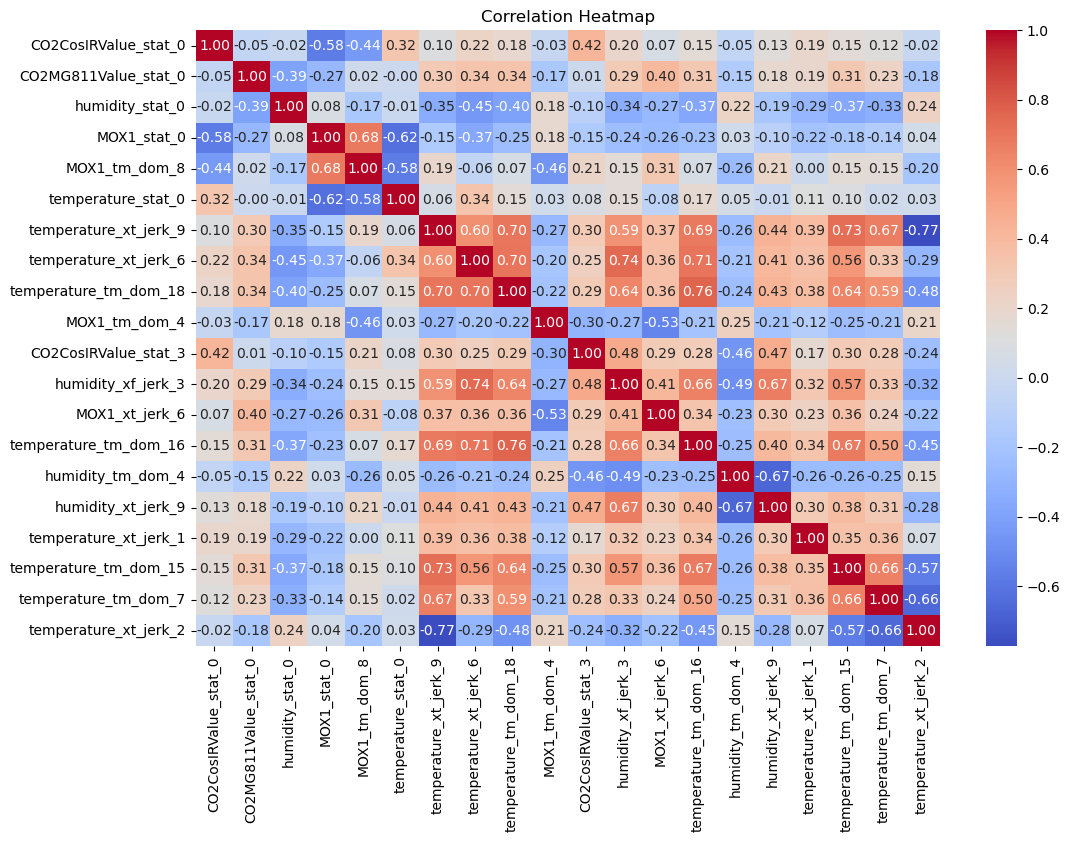

In [380]:
import seaborn as sns
correlation_matrix = X.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [381]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=296)

In [382]:
model1 = LogisticRegression(max_iter=1000,multi_class='ovr', random_state=2,C=10,penalty='l2',solver='newton-cg')
model1.fit(X_train,y_train)
y_pred=model1.predict(X_test)

/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:457: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:306: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:416: LineSearchWarning: Rounding errors prevent the line search from converging
  warn(msg, LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/utils/optimize.py:203: UserWarning: Line Search failed
  warnings.warn("Line Search failed")


In [383]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.73
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.91      0.84       117
           1       0.65      0.34      0.44       110
           2       0.73      0.82      0.78       255

    accuracy                           0.73       482
   macro avg       0.72      0.69      0.69       482
weighted avg       0.72      0.73      0.71       482



In [388]:
model2 = DecisionTreeClassifier(max_depth=5,splitter='best')
model2.fit(X_train,y_train)
y_pred=model2.predict(X_test)

In [389]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.71
Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.82      0.82       117
           1       0.53      0.33      0.40       110
           2       0.71      0.83      0.76       255

    accuracy                           0.71       482
   macro avg       0.69      0.66      0.66       482
weighted avg       0.70      0.71      0.70       482



In [415]:
model3 = RandomForestClassifier(n_estimators=200,max_depth=5)
model3.fit(X_train, y_train)

# Make predictions
y_pred = model3.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')
report = classification_report(y_test, y_pred)
print("Classification Report:\n", report)

Accuracy: 0.7634854771784232
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.85      0.87       117
           1       0.71      0.37      0.49       110
           2       0.73      0.89      0.80       255

    accuracy                           0.76       482
   macro avg       0.77      0.71      0.72       482
weighted avg       0.76      0.76      0.75       482



In [416]:
scores=[]
for i in range(1000):
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=i)
    model3 = RandomForestClassifier(n_estimators=200,max_depth=5)
    model3.fit(X_train, y_train)
    # Make predictions
    y_pred = model3.predict(X_test)
    scores.append(accuracy_score(y_test, y_pred))

In [417]:
top_5_indices = np.argsort(scores)[-5:][::-1]

print("Indices of top 5 scores:", top_5_indices)
print("Top 5 scores:", [scores[i] for i in top_5_indices])

Indices of top 5 scores: [296 322 345 670   8]
Top 5 scores: [0.7655601659751037, 0.7634854771784232, 0.7614107883817427, 0.7593360995850622, 0.7572614107883817]


In [332]:
from sklearn.ensemble import ExtraTreesClassifier
import matplotlib.pyplot as plt
model = DecisionTreeClassifier(max_depth=25,splitter='best')
model.fit(X,y)

DecisionTreeClassifier(max_depth=25)

In [333]:
y_pred = model.predict(X)

# Evaluate accuracy
accuracy = accuracy_score(y, y_pred)
print(f'Accuracy: {accuracy}')

Accuracy: 0.9641558441558442


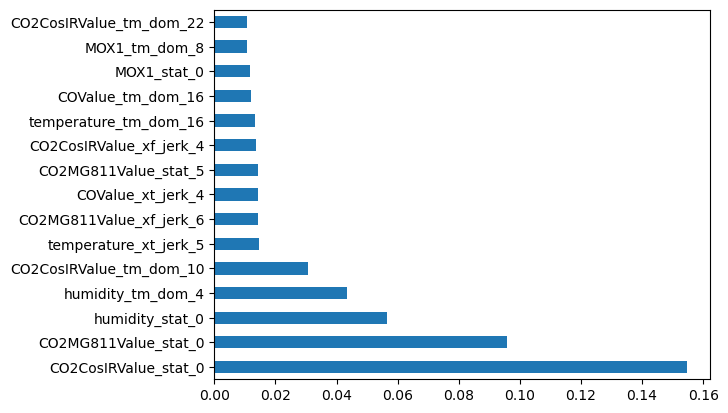

In [334]:
#plot graph of feature importances for better visualization
feat_importances = pd.Series(model.feature_importances_, index=X.columns)
feat_importances.nlargest(15).plot(kind='barh')
plt.show()

In [335]:
feat_importances.nlargest(15)

CO2CosIRValue_stat_0       0.154607
CO2MG811Value_stat_0       0.095795
humidity_stat_0            0.056350
humidity_tm_dom_4          0.043447
CO2CosIRValue_tm_dom_10    0.030784
temperature_xt_jerk_5      0.014504
CO2MG811Value_xf_jerk_6    0.014335
COValue_xt_jerk_4          0.014307
CO2MG811Value_stat_5       0.014152
CO2CosIRValue_xf_jerk_4    0.013636
temperature_tm_dom_16      0.013305
COValue_tm_dom_16          0.012126
MOX1_stat_0                0.011557
MOX1_tm_dom_8              0.010772
CO2CosIRValue_tm_dom_22    0.010634
dtype: float64

In [47]:
np.mean(scores)

0.7122614107883816

In [174]:
score1=[]
for i in [345,747,135]:
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=i)
    model3 = RandomForestClassifier(n_estimators=250,max_depth=5)
    model3.fit(X_train, y_train)
    # Make predictions
    y_pred = model3.predict(X_test)
    score1.append(accuracy_score(y_test, y_pred))
np.mean(score1)

0.7616077616077616

In [58]:
from sklearn.metrics import f1_score

In [59]:
rbf = svm.SVC(kernel='sigmoid', gamma=0.1, C=10).fit(X_train, y_train)
poly = svm.SVC(kernel='poly', degree=5, C=1).fit(X_train, y_train)

In [60]:
poly_pred = poly.predict(X_test)
rbf_pred = rbf.predict(X_test)

In [61]:
poly_accuracy = accuracy_score(y_test, poly_pred)
poly_f1 = f1_score(y_test, poly_pred, average='weighted')
print('Accuracy (Polynomial Kernel): ', "%.2f" % (poly_accuracy*100))
print('F1 (Polynomial Kernel): ', "%.2f" % (poly_f1*100))

Accuracy (Polynomial Kernel):  49.17
F1 (Polynomial Kernel):  32.42


In [62]:
rbf_accuracy = accuracy_score(y_test, rbf_pred)
rbf_f1 = f1_score(y_test, rbf_pred, average='weighted')
print('Accuracy (RBF Kernel): ', "%.2f" % (rbf_accuracy*100))
print('F1 (RBF Kernel): ', "%.2f" % (rbf_f1*100))

Accuracy (RBF Kernel):  49.17
F1 (RBF Kernel):  32.42
